# 🚀 Practice Day 36

**📅 Date:** 2026-10-16  
📁 Category: Phase 2 · SQL 중급(JOIN·서브쿼리·CASE WHEN) (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice JOIN, a subquery, and CASE WHEN in DuckDB SQL — the same university data as yesterday, solved a different way
  (DuckDB SQL의 JOIN·서브쿼리·CASE WHEN 연습 — 어제와 같은 대학교 데이터를 다른 방식으로 풀어보기)
- Find which department reaches the most students, which students take more courses than average, and how enrollments split by credit load
  (어떤 학과가 가장 많은 학생에게 도달하는지, 평균보다 많은 과목을 듣는 학생은 누구인지, 학점 구간별 수강신청 분포는 어떤지 파악하기)

---
# 📂 Dataset

**Dataset Name:** Fairhaven University — 학생·과목·수강신청 (Day 35와 동일 데이터, SQL로 재풀이) / Fairhaven University — same 3 tables as Day 35, solved with SQL this time

**Source:** Synthetically generated for practice, same generation code as Day 35 / 실습을 위해 코드로 생성, Day 35와 동일한 생성 코드

**Description:** The same `students` (60), `courses` (15), and `enrollments` (300) tables from yesterday's file. This time, instead of pandas merge, the focus is on answering similar questions using DuckDB SQL — JOIN across all three tables, a subquery, and CASE WHEN.
(어제(Day 35) 만든 것과 동일한 students(60)·courses(15)·enrollments(300) 3테이블입니다. 이번에는 pandas merge 대신 duckdb.sql()의 JOIN(3테이블 전체 연결), 서브쿼리, CASE WHEN을 사용해 비슷한 질문에 답하는 데 초점을 둡니다.)

## Dataset Preview

In [18]:
# Dataset Preview
import pandas as pd
import numpy as np
from IPython.display import display

np.random.seed(42)
rng = np.random.default_rng(42)

# --- students ---
first_names = ['Ava', 'Liam', 'Mia', 'Noah', 'Emma', 'Ethan', 'Olivia', 'Lucas', 'Sophia', 'Mason',
                'Isabella', 'Logan', 'Amelia', 'Jacob', 'Harper', 'Elijah', 'Evelyn', 'Aiden', 'Abigail', 'Carter']
last_names = ['Nguyen', 'Kim', 'Patel', 'Garcia', 'Muller', 'Rossi', 'Dubois', 'Andersson', 'Silva', 'Ivanov',
               'Chen', 'Park', 'Cohen', 'Novak', 'Haddad']

majors = ['Computer Science', 'Business', 'Biology', 'Psychology', 'Economics']
major_w = [0.24, 0.22, 0.18, 0.18, 0.18]

n_students = 60
rng2 = np.random.default_rng(11)
student_names = []
used = set()
while len(student_names) < n_students:
    name = f"{rng2.choice(first_names)} {rng2.choice(last_names)}"
    if name not in used:
        used.add(name)
        student_names.append(name)

students = pd.DataFrame({
    'student_id': [f'S{str(i).zfill(3)}' for i in range(1, n_students + 1)],
    'student_name': student_names,
    'major': rng.choice(majors, size=n_students, p=major_w)
})

# --- courses ---
courses_data = [
    ('Intro to Programming', 'Computer Science', 3),
    ('Data Structures', 'Computer Science', 4),
    ('Database Systems', 'Computer Science', 3),
    ('Marketing Principles', 'Business', 3),
    ('Financial Accounting', 'Business', 3),
    ('Organizational Behavior', 'Business', 3),
    ('Cell Biology', 'Biology', 4),
    ('Genetics', 'Biology', 4),
    ('Human Anatomy', 'Biology', 3),
    ('Intro to Psychology', 'Psychology', 3),
    ('Cognitive Science', 'Psychology', 3),
    ('Microeconomics', 'Economics', 3),
    ('Macroeconomics', 'Economics', 3),
    ('Statistics', 'Economics', 4),
    ('Calculus I', 'Mathematics', 4),
]
courses = pd.DataFrame(courses_data, columns=['course_name', 'department', 'credits'])
courses.insert(0, 'course_id', [f'C{str(i).zfill(3)}' for i in range(1, len(courses) + 1)])

# --- enrollments (every student takes 3-6 courses) ---
n_enrollments = 300
course_weight_base = rng.gamma(shape=2.0, scale=1.0, size=len(courses))
course_ids = courses['course_id'].values

enroll_pairs = set()
for sid in students['student_id']:
    n_courses = rng.integers(3, 7)
    chosen = rng.choice(course_ids, size=min(n_courses, len(course_ids)), replace=False,
                         p=course_weight_base / course_weight_base.sum())
    for cid in chosen:
        enroll_pairs.add((sid, cid))

enroll_pairs = list(enroll_pairs)
rng.shuffle(enroll_pairs)
if len(enroll_pairs) > n_enrollments:
    enroll_pairs = enroll_pairs[:n_enrollments]
else:
    while len(enroll_pairs) < n_enrollments:
        sid = rng.choice(students['student_id'].values)
        cid = rng.choice(course_ids)
        if (sid, cid) not in set(enroll_pairs):
            enroll_pairs.append((sid, cid))

semesters = ['Fall 2023', 'Spring 2024']
rows = []
for i, (sid, cid) in enumerate(enroll_pairs):
    rows.append({'enrollment_id': f'E{str(i+1).zfill(4)}', 'student_id': sid, 'course_id': cid,
                 'semester': rng.choice(semesters, p=[0.48, 0.52])})
enrollments = pd.DataFrame(rows)

print("Students:")
display(students.head())
print("\nCourses:")
display(courses.head())
print("\nEnrollments:")
display(enrollments.head())


Students:


,student_id,student_name,major
0,S001,Mia Kim,Psychology
1,S002,Elijah Andersson,Business
2,S003,Logan Ivanov,Economics
3,S004,Harper Nguyen,Psychology
4,S005,Mason Patel,Computer Science



Courses:


,course_id,course_name,department,credits
0,C001,Intro to Programming,Computer Science,3
1,C002,Data Structures,Computer Science,4
2,C003,Database Systems,Computer Science,3
3,C004,Marketing Principles,Business,3
4,C005,Financial Accounting,Business,3



Enrollments:


,enrollment_id,student_id,course_id,semester
0,E0001,S028,C012,Spring 2024
1,E0002,S026,C010,Spring 2024
2,E0003,S024,C009,Spring 2024
3,E0004,S010,C005,Spring 2024
4,E0005,S037,C006,Fall 2023


## Dataset Information

In [19]:
# Dataset Information
print("Students:", students.shape)
students.info()
print("\nCourses:", courses.shape)
courses.info()
print("\nEnrollments:", enrollments.shape)
enrollments.info()

print("\n--- Describe: Students ---")
display(students.describe(include='all'))
print("\n--- Describe: Courses ---")
display(courses.describe(include='all'))
print("\n--- Describe: Enrollments ---")
display(enrollments.describe(include='all'))


Students: (60, 3)
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   student_id    60 non-null     str  
 1   student_name  60 non-null     str  
 2   major         60 non-null     str  
dtypes: str(3)
memory usage: 1.5 KB

Courses: (15, 4)
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   course_id    15 non-null     str  
 1   course_name  15 non-null     str  
 2   department   15 non-null     str  
 3   credits      15 non-null     int64
dtypes: int64(1), str(3)
memory usage: 612.0 bytes

Enrollments: (300, 4)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   enrollment_id  300 non-null    str  
 1   stu

,student_id,student_name,major
count,60,60,60
unique,60,60,5
top,S001,Mia Kim,Psychology
freq,1,1,17



--- Describe: Courses ---


,course_id,course_name,department,credits
count,15,15,15,15.000000
unique,15,15,6,NaN
top,C001,Intro to Programming,Computer Science,NaN
freq,1,1,3,NaN
mean,NaN,NaN,NaN,3.333333
std,NaN,NaN,NaN,0.487950
min,NaN,NaN,NaN,3.000000
25%,NaN,NaN,NaN,3.000000
50%,NaN,NaN,NaN,3.000000
75%,NaN,NaN,NaN,4.000000



--- Describe: Enrollments ---


,enrollment_id,student_id,course_id,semester
count,300,300,300,300
unique,300,60,15,2
top,E0001,S024,C012,Fall 2023
freq,1,7,37,151


---
# ❓ Business Questions

1. **(Analysis — JOIN)** Joining all three tables, how many unique students does each department reach through its courses?
   (3개 테이블을 JOIN했을 때, 각 학과는 몇 명의 고유 학생에게 도달하는가?)
2. **(Analysis — Subquery)** Using a subquery to find the average number of courses per student, which students are enrolled in more courses than that average?
   (서브쿼리로 학생 1명당 평균 수강과목 수를 구했을 때, 그 평균보다 더 많은 과목을 신청한 학생은?)
3. **(Analysis — CASE WHEN)** Using CASE WHEN to bucket each enrollment by its course's credit load (3 vs 4 credits), how many enrollments fall into each bucket?
   (CASE WHEN으로 과목 학점(3학점 vs 4학점)에 따라 수강신청을 구간으로 나누면, 구간별 건수는?)
4. **(Visualization)** Compare how many unique students each department reaches.
   (학과별 고유 학생 도달 수를 비교하면?)
5. **(Visualization)** Compare enrollment counts between the light-credit and heavy-credit course groups.
   (경(輕)학점·중(重)학점 과목 그룹 간 수강신청 건수를 비교하면?)

---
# 🔍 Data Cleaning Check


In [20]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("===== students =====")
print("Missing values")
print(students.isnull().sum())
print("\nDuplicate rows:", students.duplicated().sum())
print("\nDtypes")
print(students.dtypes)
print("\nColumn names")
print(students.columns.tolist())
obj_cols = students.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(students[obj_cols].nunique())
print()

print("===== courses =====")
print("Missing values")
print(courses.isnull().sum())
print("\nDuplicate rows:", courses.duplicated().sum())
print("\nDtypes")
print(courses.dtypes)
print("\nColumn names")
print(courses.columns.tolist())
obj_cols = courses.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(courses[obj_cols].nunique())
print()

print("===== enrollments =====")
print("Missing values")
print(enrollments.isnull().sum())
print("\nDuplicate rows:", enrollments.duplicated().sum())
print("\nDtypes")
print(enrollments.dtypes)
print("\nColumn names")
print(enrollments.columns.tolist())
obj_cols = enrollments.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(enrollments[obj_cols].nunique())
print()


===== students =====
Missing values
student_id      0
student_name    0
major           0
dtype: int64

Duplicate rows: 0

Dtypes
student_id      str
student_name    str
major           str
dtype: object

Column names
['student_id', 'student_name', 'major']

Text columns — unique counts
student_id      60
student_name    60
major            5
dtype: int64

===== courses =====
Missing values
course_id      0
course_name    0
department     0
credits        0
dtype: int64

Duplicate rows: 0

Dtypes
course_id        str
course_name      str
department       str
credits        int64
dtype: object

Column names
['course_id', 'course_name', 'department', 'credits']

Text columns — unique counts
course_id      15
course_name    15
department      6
dtype: int64

===== enrollments =====
Missing values
enrollment_id    0
student_id       0
course_id        0
semester         0
dtype: int64

Duplicate rows: 0

Dtypes
enrollment_id    str
student_id       str
course_id        str
semester        

---
# 📊 Analysis

## Question 1

**Question:** Joining all three tables, how many unique students does each department reach through its courses? (3개 테이블 JOIN 시, 학과별 고유 학생 도달 수는?)

**Result:** Business **50**, Economics **48**, Psychology **41**, Computer Science **37**, Biology **37**, Mathematics **14**.  
(Business 50명, Economics 48명, Psychology 41명, Computer Science 37명, Biology 37명, Mathematics 14명)

**Insight:** Business reaches **36** more students than Mathematics and **2** more than Economics. Computer Science and Biology are tied at **37**.  
(Business는 Mathematics보다 36명, Economics보다 2명 많음. Computer Science와 Biology는 37명으로 같음)


In [21]:
# Question 1 (DuckDB, JOIN): unique students reached by each department
import duckdb

count_by_department = duckdb.sql("""
    SELECT
        c.department,
        COUNT(DISTINCT e.student_id) AS unique_students
    FROM enrollments e
    JOIN courses c ON e.course_id = c.course_id
    GROUP BY c.department
    ORDER BY unique_students DESC
""").df()

count_by_department

,department,unique_students
0,Business,50
1,Economics,48
2,Psychology,41
3,Computer Science,37
4,Biology,37
5,Mathematics,14


## Question 2

**Question:** Using a subquery to find the average number of courses per student, which students are enrolled in more courses than that average? (평균 수강과목 수보다 많이 신청한 학생은?)

**Result:** **27** students are above the average. Carter Rossi (S024) has **7** courses. The other **26** have **6**.  
(평균보다 많은 학생은 27명. Carter Rossi(S024)는 7과목, 나머지 26명은 6과목)

**Insight:** Carter Rossi is **1** course above the **26** students tied at **6**.  
(Carter Rossi는 6과목으로 묶인 26명보다 1과목 많음)


In [22]:
# Question 2 (DuckDB, subquery): students enrolled in more courses than the average student

duckdb.sql("""
    SELECT
        s.student_id,
        s.student_name,
        COUNT(DISTINCT e.course_id) AS course_count
    FROM enrollments e
    JOIN students s ON e.student_id = s.student_id
    GROUP BY s.student_id, s.student_name
    HAVING COUNT(DISTINCT e.course_id) > (
        SELECT AVG(course_count)
        FROM (
            SELECT student_id, COUNT(DISTINCT course_id) AS course_count
            FROM enrollments
            GROUP BY student_id
        ) AS student_course_counts
    )
    ORDER BY course_count DESC
""").df()


,student_id,student_name,course_count
0,S024,Carter Rossi,7
1,S050,Evelyn Chen,6
2,S037,Logan Novak,6
3,S004,Harper Nguyen,6
4,S052,Noah Cohen,6
5,S059,Ava Dubois,6
6,S003,Logan Ivanov,6
7,S010,Aiden Rossi,6
8,S045,Harper Rossi,6
9,S001,Mia Kim,6


## Question 3

**Question:** Using CASE WHEN to bucket each enrollment by credit load, how many enrollments fall into each bucket? (CASE WHEN으로 학점 구간을 나누면 구간별 건수는?)

**Result:** Light Credit (3 credits) has **238** enrollments. Heavy Credit (4 credits) has **62**.  
(Light Credit(3학점) 238건, Heavy Credit(4학점) 62건)

**Insight:** Light Credit is **176** above Heavy Credit. The two buckets add up to **300** enrollments.  
(Light Credit가 Heavy Credit보다 176건 많음. 두 구간을 합치면 300건)


In [23]:
# Question 3 (DuckDB, CASE WHEN): bucket enrollments by course credit load

tier_by_credit = duckdb.sql("""
    SELECT
        CASE
            WHEN c.credits = 3 THEN 'Light Credit'
            WHEN c.credits = 4 THEN 'Heavy Credit'
        END AS credit_tier,
        COUNT(e.enrollment_id) AS enrollment_count,
    FROM enrollments e
    JOIN courses c ON e.course_id = c.course_id
    GROUP BY credit_tier
    ORDER BY enrollment_count DESC
""").df()

tier_by_credit

,credit_tier,enrollment_count
0,Light Credit,238
1,Heavy Credit,62


---
# 📈 Visualization

**Chart 1:** Bar chart — unique students reached by department (막대그래프: 학과별 고유 학생 도달 수)

*Interpretation:* The bars fall from Business (**50**) to Economics (**48**), Psychology (**41**), then Computer Science and Biology (both **37**), and Mathematics (**14**).  
(막대는 Business 50, Economics 48, Psychology 41, 그다음 Computer Science와 Biology가 둘 다 37, Mathematics 14 순으로 짧아짐)

---

**Chart 2:** Bar chart — enrollment count by credit tier (막대그래프: 학점 구간별 수강신청 건수)

*Interpretation:* Light Credit is **238** and Heavy Credit is **62**. The Light bar is **176** taller.  
(Light Credit는 238건, Heavy Credit는 62건. Light 막대가 176 더 김)


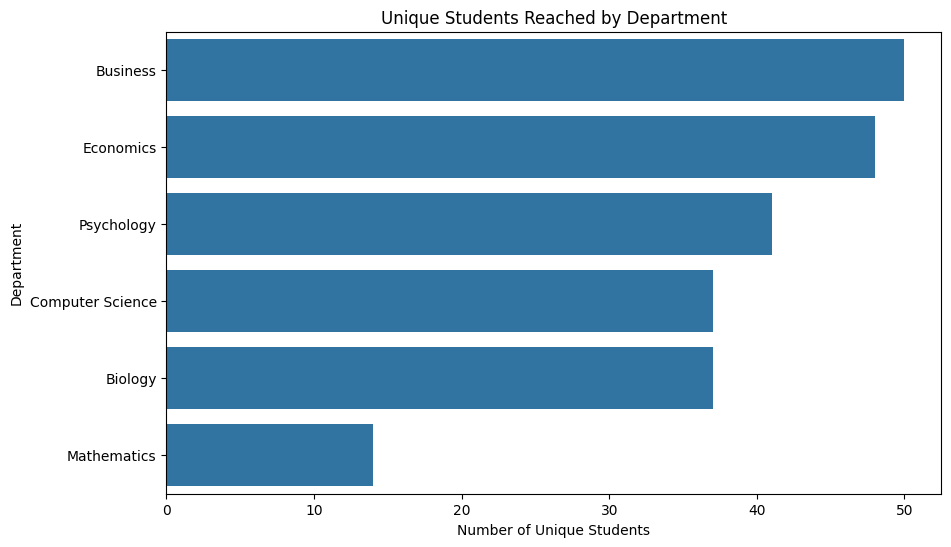

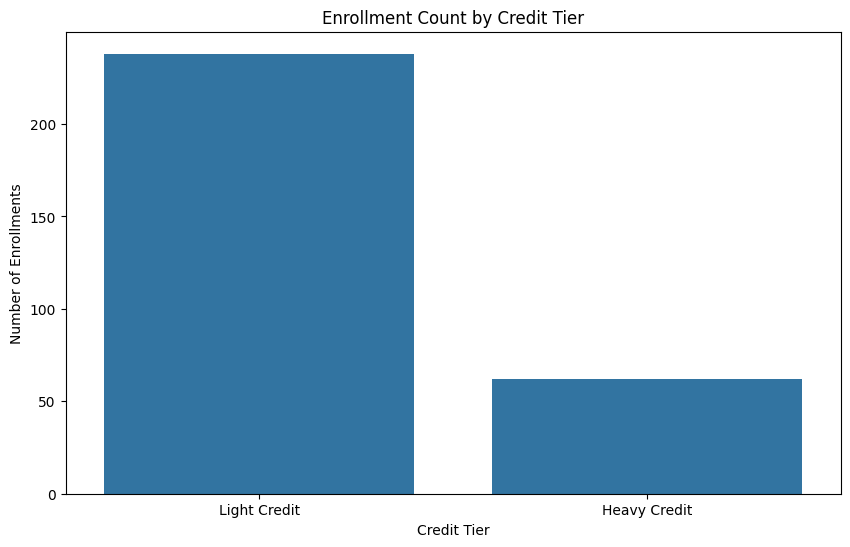

In [29]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: unique students reached by department (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='unique_students', y='department', data=count_by_department, ax=ax)
plt.title('Unique Students Reached by Department')
plt.xlabel('Number of Unique Students')
plt.ylabel('Department')
plt.show()

# Chart 2: enrollment count by credit tier (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='credit_tier', y='enrollment_count', data=tier_by_credit, ax=ax)
plt.title('Enrollment Count by Credit Tier')
plt.xlabel('Credit Tier')
plt.ylabel('Number of Enrollments')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Business reaches **50** distinct students, the most of six departments. Mathematics reaches **14**.  
  (여섯 학과 중 Business가 50명으로 가장 많은 학생에게 도달함. Mathematics는 14명)
- **27** students take more courses than the average. Carter Rossi takes **7**, and **26** students take **6**.  
  (평균보다 많은 과목을 듣는 학생은 27명. Carter Rossi는 7과목, 26명은 6과목)
- 3-credit courses have **238** enrollments. 4-credit courses have **62**.  
  (3학점 과목 수강은 238건. 4학점 과목 수강은 62건)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Look at Mathematics, which reaches **14** students, against Business at **50**.  
   (14명에게 도달하는 Mathematics를, 50명인 Business와 비교해서 보기)
2. Carter Rossi is the only student at **7** courses. The next group is **26** students at **6**.  
   (7과목인 학생은 Carter Rossi뿐. 다음은 6과목인 26명)
3. Most enrollments are already 3 credits (**238** of **300**). A new 4-credit course would sit in the smaller bucket of **62**.  
   (수강 300건 중 238건이 이미 3학점. 4학점 과목을 새로 열면 62건짜리 구간에 들어감)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- Q2 grouped by `e.student_name`, but that column is on `students`, not `enrollments`. DuckDB raised `Binder Error`.  
  (Q2에서 e.student_name으로 묶었지만 그 열은 enrollments가 아니라 students에 있음. DuckDB가 Binder Error를 냄)
- The inner count of courses per student had no `GROUP BY student_id`, so it was not one count per student.  
  (안쪽의 학생별 과목 수에 GROUP BY student_id가 없어서, 학생마다 하나씩인 건수가 아니었음)  


---
# ✅ What I Learned
*Today's biggest lesson*

- `COUNT(DISTINCT student_id)` after joining `enrollments` to `courses` is how many different students a department reaches.  
  (enrollments를 courses에 조인한 뒤 COUNT(DISTINCT student_id)가 학과가 도달한 서로 다른 학생 수)
- A share of students above the average uses `HAVING COUNT(...) > (SELECT AVG(...) FROM (학생별 건수))`. The inner query needs its own `GROUP BY`.  
  (평균보다 많은 학생은 HAVING COUNT(...) > (SELECT AVG(...) FROM (학생별 건수)). 안쪽 쿼리에도 GROUP BY가 필요함)
- `CASE WHEN credits = 3` and `WHEN credits = 4` put each enrollment into Light Credit or Heavy Credit before `COUNT`.  
  (CASE WHEN credits = 3, WHEN credits = 4로 수강 한 건을 Light Credit 또는 Heavy Credit에 넣은 뒤 COUNT)  


---
# 🧠 Reflection

**What was difficult?**  
Writing the subquery that compares each student with the average course count.  
(학생별 과목 수를 평균과 비교하는 서브쿼리를 쓰는 것)

**Why?**  
`student_name` is not on `enrollments`, and the average needs a per-student count, not one count of every row.  
(student_name은 enrollments에 없고, 평균은 전체 한 건이 아니라 학생별 건수여야 함)

**How did I solve it?**  
Joined `students` for the name, and added `GROUP BY student_id` inside the average subquery.  
(이름은 students를 조인하고, 평균 서브쿼리 안에 GROUP BY student_id를 넣음)

**What would I do differently next time?**  
Check which table owns the column before writing `e.column`, and group the inner count first.  
(e.column을 쓰기 전에 그 열의 테이블을 확인하고, 안쪽 건수부터 그룹하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The department reach, the above-average student list, and the credit buckets are clear. The nested average still needs a second look.  
(학과별 도달 학생, 평균 초과 학생 목록, 학점 구간은 이해함. 중첩된 평균은 한 번 더 봐야 함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The JOIN and CASE WHEN were short. The subquery was the hard part.  
(JOIN과 CASE WHEN은 짧았고, 어려운 부분은 서브쿼리였음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 37 — visualization storytelling (Round 3/5)  
  (Seaborn 시각화 스토리텔링 복습)  
